# Release Audit

## tl;dr
The extended audit separates adjusted association, predictive usefulness and measurement limitations.

## Context & Methods
The primary specification is unchanged. Alternatives are exploratory and reuse the same observations. See [research report](../docs/research_report.md) for the detailed conclusion and plain-language explanation.

### Key Assumptions
Regular-season PBP Stats aggregates; lagged profiles; observational comparisons. See [methodology](../docs/methodology_notes.md).

## Data
Run the cached pipeline and offline analysis before this notebook. No network requests are made here.

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
from IPython.display import display, Image, Markdown
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'data_pipeline.py').exists())
DATA = ROOT / 'data' / 'processed'
import sys
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
pd.set_option('display.max_columns', 12)


## Results

### Data coverage and membership repairs

In [2]:
audit=pd.read_csv(ROOT/'docs'/'coverage_audit.csv')
display(audit.groupby('season')[['rows','membership_alias_rows','plusminus_discrepancy_lineups']].sum())
display(pd.read_csv(ROOT/'docs'/'pilot_reproduction.csv').filter(like='_difference').abs().max())

,rows,membership_alias_rows,plusminus_discrepancy_lineups
season,,,
2022-23,16752,0,0
2023-24,15870,0,0
2024-25,17941,2,25
2025-26,19501,0,0


coefficient_difference    4.440892e-15
se_difference             1.332268e-14
ci_low_difference         3.197442e-14
ci_high_difference        2.486900e-14
dtype: float64

### Independent official benchmark

In [3]:
official=pd.read_csv(ROOT/'docs'/'official_reconciliation.csv')
display(official.filter(like='_difference').abs().max())
print('All 30 teams, 2022-23 games and scoring only; this does not validate possessions or lineup membership.')

All 30 teams, 2022-23 games and scoring only; this does not validate possessions or lineup membership.


games_difference              0
points_difference             0
opponent_points_difference    0
dtype: int64

### Season and specification estimates

,scope,specification,threshold,coefficient,ci_low,ci_high,lineups
6,balanced_source_seasons,primary,25,-1.320409,-12.827880,10.187061,1780
13,balanced_source_seasons,primary,50,-0.291468,-16.319630,15.736694,808
20,balanced_source_seasons,primary,100,-3.696715,-19.530969,12.137539,311
27,pooled,common_denominator_outcome,50,-0.303974,-8.590306,7.982358,1537
34,pooled,provider_plusminus_outcome,50,-0.313920,-8.587798,7.959958,1537
41,pooled,exclude_provider_plusminus_discrepancies,50,-0.798902,-9.377260,7.779457,1535
48,pooled,primary,25,-1.349874,-8.462501,5.762753,3341
55,pooled,primary,50,-0.440605,-9.130425,8.249215,1537
62,pooled,primary,100,-4.160924,-15.642279,7.320430,599
69,2022-23,primary,25,-6.318805,-22.652006,10.014396,787


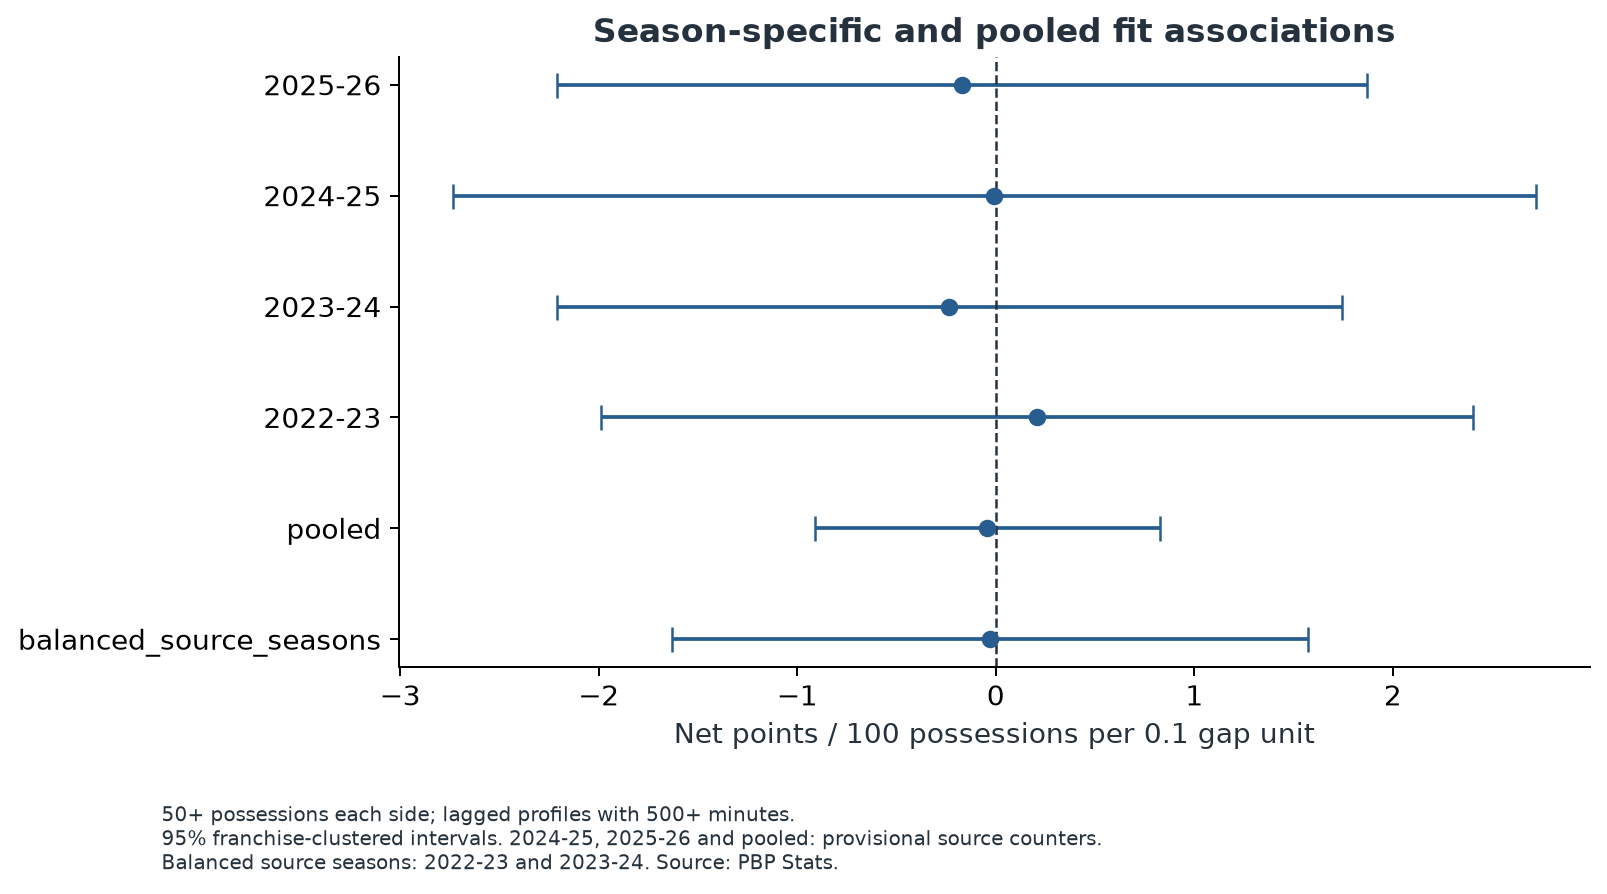

In [4]:
extended=pd.read_csv(ROOT/'docs'/'extended_coefficients.csv')
display(extended[extended.term==extended.fit_column][['scope','specification','threshold','coefficient','ci_low','ci_high','lineups']])
display(Image(filename=str(ROOT/'figures'/'season_effects.png')))

### Small-cluster inference and identification

In [5]:
display(pd.DataFrame(json.loads((ROOT/'docs'/'inference_diagnostics.json').read_text())).T)
print('Bootstrap and jackknife retain franchise dependence assumptions; Kish counts are exposure summaries, not independent sample sizes.')

Bootstrap and jackknife retain franchise dependence assumptions; Kish counts are exposure summaries, not independent sample sizes.


,seed,draws,observed_t,wild_cluster_p,wild_null,jackknife_se,...,leave_franchise_out_max,clusters,conditional_fit_variance_share,slope_leverage_max,lineup_weight_kish,note
balanced_source_seasons,20261016,1999,-0.037192,0.9585,0,6.223761,...,1.837254,30,0.735263,0.033553,304.409983,"Kish count describes exposure concentration, n..."
pooled,20261016,1999,-0.1037,0.898,0,3.271281,...,0.700855,30,0.80389,0.020792,609.904818,"Kish count describes exposure concentration, n..."
2022-23,20261016,1999,0.195857,0.8065,0,8.764285,...,6.478007,24,0.66455,0.058795,153.249826,"Kish count describes exposure concentration, n..."
2023-24,20261016,1999,-0.242896,0.753,0,7.737975,...,0.674941,29,0.768758,0.057003,155.834078,"Kish count describes exposure concentration, n..."
2024-25,20261016,1999,-0.00547,0.994,0,10.879097,...,4.992722,27,0.748096,0.064231,159.480865,"Kish count describes exposure concentration, n..."
2025-26,20261016,1999,-0.170973,0.8315,0,7.888798,...,1.526963,26,0.832635,0.083097,152.131288,"Kish count describes exposure concentration, n..."


### Forward prediction

,model,rmse,mae,rows,lineups,weight_sum,test_season,train_seasons
0,baseline,10.718173,7.256421,1226,450,71710.5,2023-24,2022-23
1,complementarity,10.720560,7.256438,1226,450,71710.5,2023-24,2022-23
2,baseline,10.563475,7.341905,1115,378,61314.5,2024-25,"2022-23,2023-24"
3,complementarity,10.563546,7.342067,1115,378,61314.5,2024-25,"2022-23,2023-24"
4,baseline,11.484052,8.184457,962,351,48867.0,2025-26,"2022-23,2023-24,2024-25"
5,complementarity,11.483968,8.184185,962,351,48867.0,2025-26,"2022-23,2023-24,2024-25"


{'delta_rmse': 0.0009271615528660959,
 'ci_low': -0.00572336983689814,
 'ci_high': 0.006855432716386908,
 'draws': 1999,
 'seed': 20261016,
 'clubs': 30,
 'interpretation': 'Positive means worse with fit. Conditional on fitted models; training variability and cross-franchise dependence not represented.'}

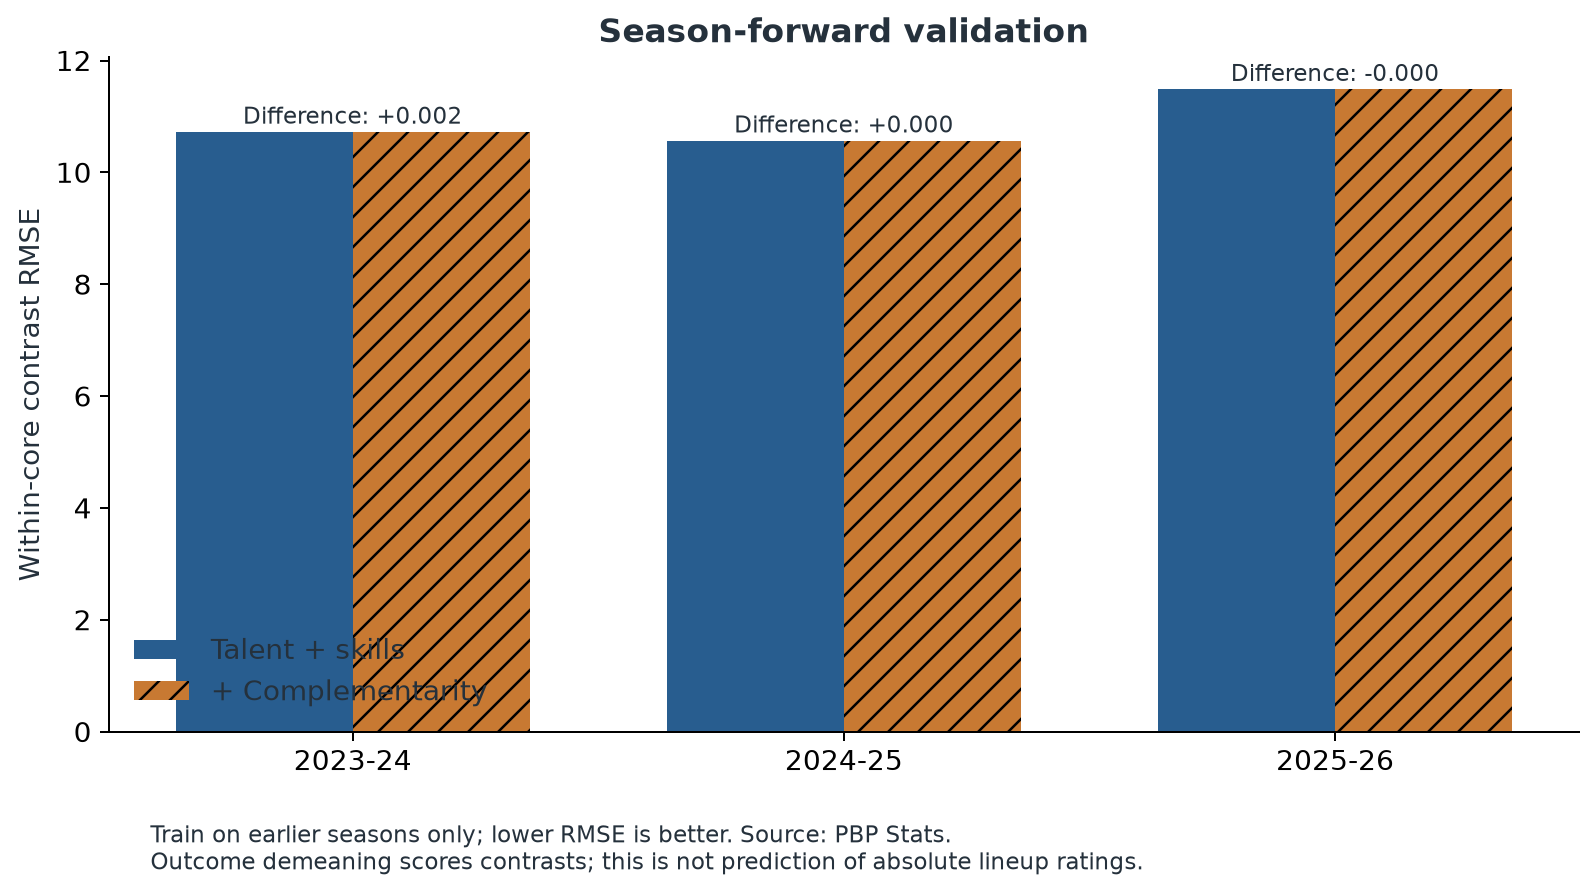

In [6]:
path=ROOT/'docs'/'season_forward_validation.csv'
if path.stat().st_size>5:
    display(pd.read_csv(path))
    display(json.loads((ROOT/'docs'/'predictive_uncertainty.json').read_text()))
    display(Image(filename=str(ROOT/'figures'/'forward_prediction.png')))
else:
    print('Only one outcome season; forward validation is unavailable.')

### Knicks illustration selected by exposure

Zero gap closure does not mean zero player value. The metric rewards only the selected below-average dimension.


,season,fifth_id_name,possessions,weakest_skill,deficiency_gap,complementarity
0,2024-25,Jalen Brunson,1889.5,interior,0.341449,0.0
1,2024-25,Miles McBride,361.0,interior,0.341449,0.0
2,2024-25,Cameron Payne,200.0,interior,0.341449,0.0
3,2024-25,Delon Wright,164.0,interior,0.341449,0.0


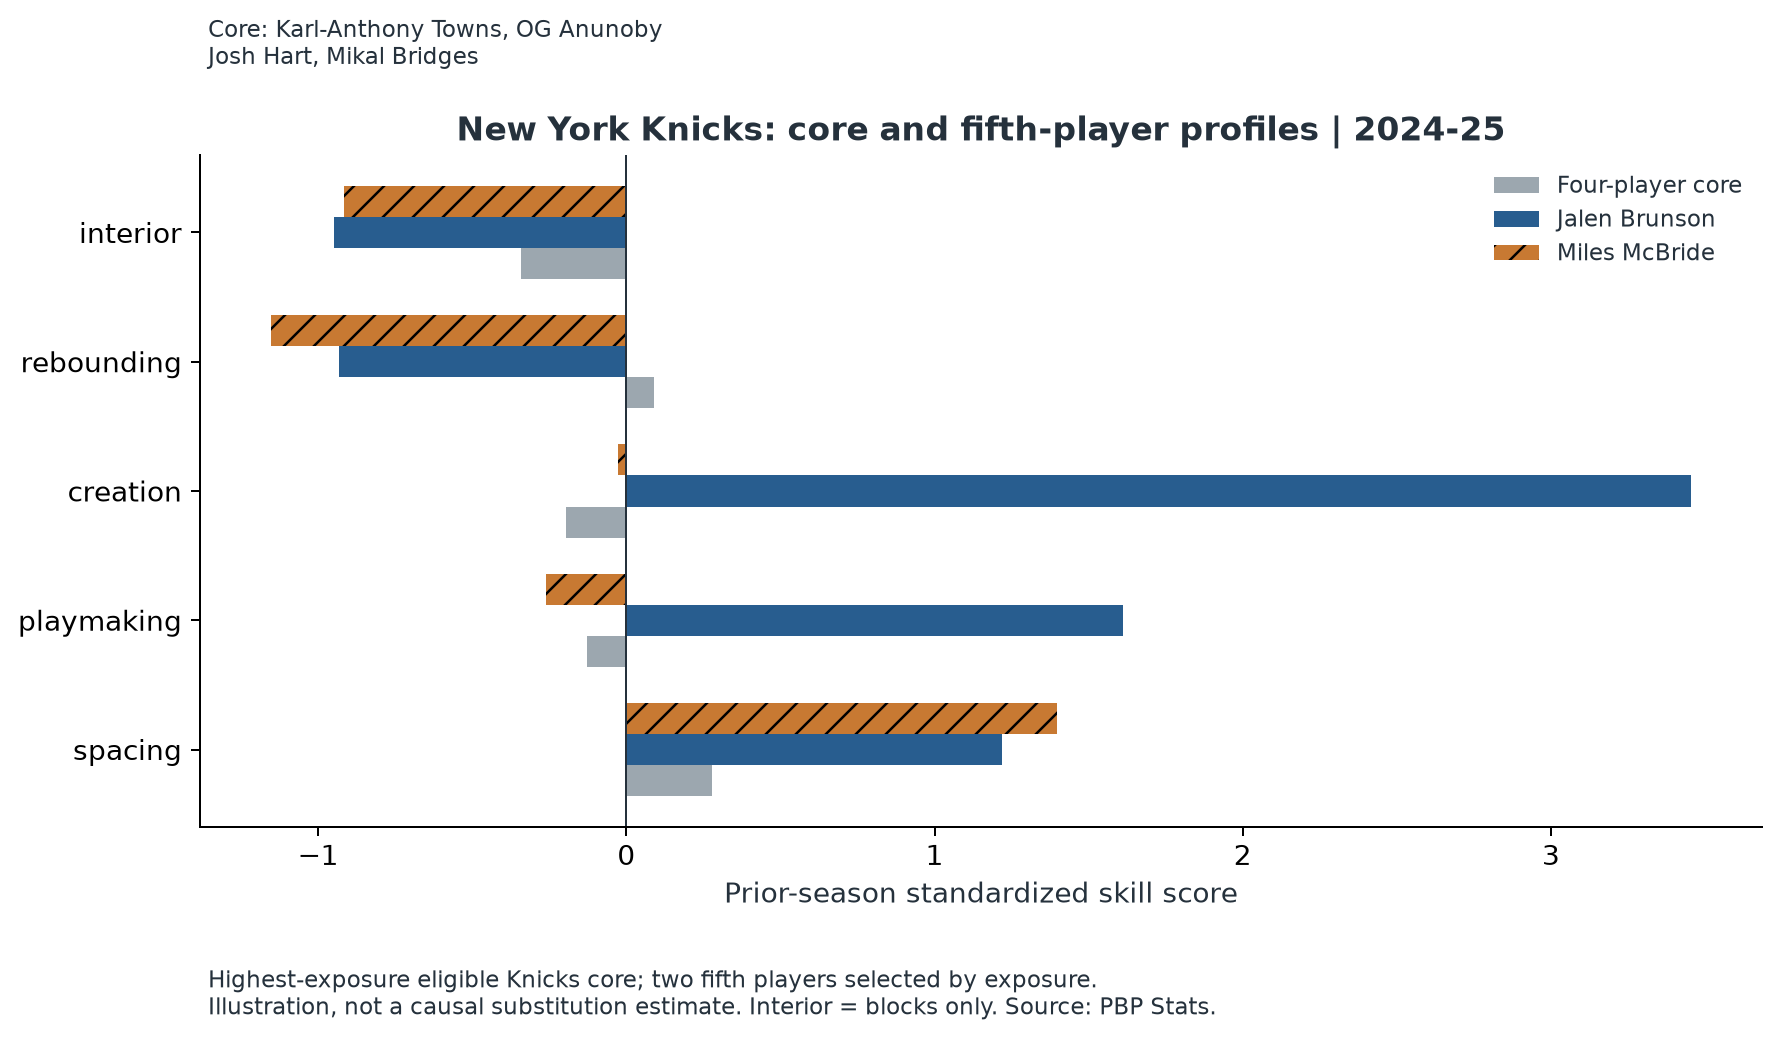

In [7]:
display(pd.read_csv(ROOT/'docs'/'knicks_example.csv')[['season','fifth_id_name','possessions','weakest_skill','deficiency_gap','complementarity']])
display(Image(filename=str(ROOT/'figures'/'knicks_example.png')))
print('Zero gap closure does not mean zero player value. The metric rewards only the selected below-average dimension.')

## Takeaways
Use held-out performance to judge the extra information supplied by the metric. A null association is not proof that basketball fit is irrelevant. No causal substitution or roster recommendation follows from these aggregates.